In [3]:
import pandas as pd


In [4]:
df = pd.read_csv("../Dataset/food_delivery_orders_dataset.csv")

In [14]:
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  str    
 1   customer_id                          50000 non-null  str    
 2   restaurant_id                        50000 non-null  str    
 3   driver_id                            50000 non-null  str    
 4   order_timestamp                      50000 non-null  str    
 5   order_date                           50000 non-null  str    
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  str    
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  str    
 10  delivery_area                        50000 non-null  str    
 11  customer_age                         50

In [16]:
df["order_status"].value_counts()

order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df["order_id"].nunique()

50000

In [19]:
df["customer_id"].nunique()

4979

In [20]:
df["customer_id"].value_counts().head(10)

customer_id
CUS_00001    4510
CUS_00004    2319
CUS_00003    2138
CUS_00002    2065
CUS_00005    1506
CUS_00006    1297
CUS_00007    1214
CUS_00008    1102
CUS_00009     823
CUS_00011     686
Name: count, dtype: int64

In [21]:
df["customer_id"].value_counts().value_counts().sort_index()

count
1       1998
2       1095
3        558
4        284
5        169
        ... 
1506       1
2065       1
2138       1
2319       1
4510       1
Name: count, Length: 128, dtype: int64

In [22]:
df["restaurant_id"].nunique()

250

In [23]:
df["restaurant_id"].value_counts().head(10)

restaurant_id
RES_0001    8837
RES_0004    4261
RES_0003    3967
RES_0002    3553
RES_0009    1621
RES_0005    1364
RES_0008    1265
RES_0006    1141
RES_0010    1038
RES_0007     959
Name: count, dtype: int64

In [24]:
df["restaurant_id"].value_counts()

restaurant_id
RES_0001    8837
RES_0004    4261
RES_0003    3967
RES_0002    3553
RES_0009    1621
            ... 
RES_0237      13
RES_0248      13
RES_0227      12
RES_0243      11
RES_0242      11
Name: count, Length: 250, dtype: int64

In [25]:
df["driver_id"].nunique()

200

In [26]:
df["order_date"].min(), df["order_date"].max()

('2025-10-01', '2025-10-30')

In [27]:
df["order_timestamp"].head()

0    2025-10-05 15:54:00
1    2025-10-01 20:00:00
2    2025-10-07 18:24:00
3    2025-10-30 16:54:00
4    2025-10-15 18:34:00
Name: order_timestamp, dtype: str

In [28]:
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])

In [30]:
df["order_timestamp"].dtype

dtype('<M8[us]')

In [31]:
df["order_date"].dtype

<StringDtype(na_value=nan)>

In [32]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [33]:
df["order_date"].dtype

dtype('<M8[us]')

In [34]:
df.isnull().sum()

order_id                                   0
customer_id                                0
restaurant_id                              0
driver_id                                  0
order_timestamp                            0
order_date                                 0
order_hour                                 0
day_of_week                                0
is_weekend                                 0
city                                       0
delivery_area                              0
customer_age                               0
customer_type                              0
restaurant_type                            0
restaurant_primary_category                0
restaurant_rating                          0
items_count                                0
subtotal                                   0
discount_percent                           0
tax_amount                                 0
service_fee                                0
delivery_fee                               0
order_tota

In [35]:
df.groupby("order_status")[["tip_amount", "actual_delivery_time_minutes", "late_delivery", "customer_rating"]].apply(lambda x: x.isnull().sum())

,tip_amount,actual_delivery_time_minutes,late_delivery,customer_rating
order_status,,,,
Cancelled,868,868,868,868
Completed,0,0,0,0


In [36]:
df.groupby("order_status")["cancellation_reason"].apply(lambda x: x.isnull().sum())

order_status
Cancelled        0
Completed    49132
Name: cancellation_reason, dtype: int64

In [37]:
df["order_status"].unique()

<ArrowStringArray>
['Completed', 'Cancelled']
Length: 2, dtype: str

In [38]:
df["order_status"].value_counts()

order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

In [39]:
df[["subtotal", "discount_percent", "tax_amount", "service_fee", "delivery_fee", "order_total", "tip_amount", "distance_km", "restaurant_preparation_time_minutes", "estimated_delivery_time_minutes", "actual_delivery_time_minutes"]].min()

subtotal                                5.10
discount_percent                        0.00
tax_amount                              0.57
service_fee                             0.13
delivery_fee                            0.00
order_total                             4.87
tip_amount                              0.00
distance_km                             0.80
restaurant_preparation_time_minutes     5.00
estimated_delivery_time_minutes         8.00
actual_delivery_time_minutes           10.00
dtype: float64

In [40]:
df[["customer_age", "items_count", "discount_percent", "order_total", "distance_km", "delivery_partner_experience_months", "restaurant_preparation_time_minutes", "estimated_delivery_time_minutes", "actual_delivery_time_minutes"]].max()

customer_age                            55.00
items_count                             10.00
discount_percent                        20.00
order_total                            443.21
distance_km                             20.00
delivery_partner_experience_months      60.00
restaurant_preparation_time_minutes     73.00
estimated_delivery_time_minutes        128.00
actual_delivery_time_minutes           172.00
dtype: float64

In [41]:
df["city"].unique()

<ArrowStringArray>
['City_C', 'City_A', 'City_B', 'City_D']
Length: 4, dtype: str

In [42]:
df["restaurant_primary_category"].unique()

<ArrowStringArray>
['Healthy', 'Dessert', 'Local', 'Pizza', 'Burger', 'Asian']
Length: 6, dtype: str

In [43]:
df["customer_type"].unique()

<ArrowStringArray>
['Premium', 'Regular', 'New']
Length: 3, dtype: str

In [44]:
df["payment_method"].unique()

<ArrowStringArray>
['Credit Card', 'Cash', 'Digital Wallet']
Length: 3, dtype: str

In [45]:
df["weather"].unique()

<ArrowStringArray>
['Rain', 'Cloudy', 'Clear', 'Storm']
Length: 4, dtype: str

In [46]:
df["traffic_level"].unique()

<ArrowStringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

In [47]:
df["day_of_week"].unique()

<ArrowStringArray>
['Sunday', 'Wednesday', 'Tuesday', 'Thursday', 'Friday', 'Monday', 'Saturday']
Length: 7, dtype: str

In [48]:
df["order_hour"].unique()

array([15, 20, 18, 16, 14, 19,  7, 12, 11,  3, 17,  8, 21,  9, 13, 22, 10,
        2,  6,  1,  4,  0, 23,  5])

In [49]:
df["is_weekend"].unique()

array([1, 0])

In [50]:
df["restaurant_type"].unique()

<ArrowStringArray>
['Casual Dining', 'Cafe', 'Fast Food', 'Fine Dining']
Length: 4, dtype: str

In [51]:
df["delivery_area"].unique()

<ArrowStringArray>
[ 'City_C_Area_3',  'City_A_Area_1',  'City_B_Area_6', 'City_D_Area_10',
  'City_C_Area_4',  'City_B_Area_9',  'City_A_Area_8',  'City_C_Area_8',
  'City_A_Area_6', 'City_A_Area_10',  'City_A_Area_3',  'City_B_Area_5',
  'City_D_Area_1',  'City_B_Area_8',  'City_B_Area_3',  'City_C_Area_9',
 'City_B_Area_10',  'City_A_Area_7',  'City_D_Area_6',  'City_A_Area_2',
  'City_A_Area_5', 'City_C_Area_10',  'City_A_Area_9',  'City_C_Area_7',
  'City_B_Area_4',  'City_C_Area_1',  'City_B_Area_1',  'City_D_Area_8',
  'City_A_Area_4',  'City_B_Area_7',  'City_B_Area_2',  'City_D_Area_9',
  'City_C_Area_5',  'City_D_Area_5',  'City_C_Area_6',  'City_D_Area_2',
  'City_C_Area_2',  'City_D_Area_7',  'City_D_Area_3',  'City_D_Area_4']
Length: 40, dtype: str

In [52]:
df["customer_age"].dtype

dtype('int64')

In [53]:
df["restaurant_rating"].dtype

dtype('float64')

In [54]:
df["restaurant_rating"].min(), df["restaurant_rating"].max()

(np.float64(2.8), np.float64(5.0))

In [55]:
df["delivery_partner_rating"].min(), df["delivery_partner_rating"].max()

(np.float64(3.2), np.float64(5.0))

In [56]:
df["order_total"].min(), df["order_total"].max()

(np.float64(4.87), np.float64(443.21))

In [57]:
df["cancellation_reason"].value_counts()

cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64

In [58]:
df["late_delivery"].unique()

array([ 0.,  1., nan])

In [59]:
df[df["order_status"] == "Completed"]["late_delivery"].unique()

array([0., 1.])

In [60]:
df["customer_rating"].min(), df["customer_rating"].max()

(np.float64(1.8), np.float64(5.0))

In [61]:
df[df["order_status"] == "Completed"]["customer_rating"].min(), df[df["order_status"] == "Completed"]["customer_rating"].max()

(np.float64(1.8), np.float64(5.0))

In [62]:
df[["estimated_delivery_time_minutes", "actual_delivery_time_minutes"]].isnull().sum()

estimated_delivery_time_minutes      0
actual_delivery_time_minutes       868
dtype: int64

In [63]:
df[df["order_status"] == "Completed"][["estimated_delivery_time_minutes", "actual_delivery_time_minutes", "late_delivery"]].head(10)


,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery
0,25,29.0,0.0
1,20,24.0,0.0
2,63,72.0,1.0
3,23,31.0,1.0
4,32,42.0,1.0
5,32,39.0,1.0
6,27,31.0,0.0
7,20,22.0,0.0
8,37,40.0,0.0
9,25,22.0,0.0


In [64]:
df[["subtotal", "discount_percent", "tax_amount", "service_fee", "delivery_fee", "order_total"]].head(5)

,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total
0,64.82,0,9.07,2.40,0.00,76.29
1,13.03,0,1.82,0.84,3.25,18.94
2,10.12,10,1.28,0.56,7.90,18.85
3,8.86,10,1.12,0.40,4.70,14.19
4,15.08,20,1.69,0.65,5.05,19.45


In [66]:
df["calculated_total"] = (
    df["subtotal"]
    - (df["subtotal"] * df["discount_percent"] / 100)
    + df["tax_amount"]
    + df["service_fee"]
    + df["delivery_fee"]
)

In [67]:
(df["order_total"] - df["calculated_total"]).abs().max()


np.float64(0.005000000000052296)

In [68]:
df.drop(columns=["calculated_total"], inplace=True)

In [69]:
df["order_id"].duplicated().sum()

np.int64(0)

In [70]:
df.to_csv("../Dataset/food_delivery_orders_cleaned.csv", index=False)

In [1]:
df["order_hour"].value_counts().sort_index()

NameError: name 'df' is not defined

In [5]:
df["order_hour"].value_counts().sort_index()

order_hour
0      429
1      437
2      408
3      407
4      425
5      404
6      868
7     1301
8     1675
9     2106
10    2618
11    3441
12    4208
13    3836
14    3098
15    1610
16    1725
17    2121
18    3803
19    4746
20    4318
21    3382
22    1734
23     900
Name: count, dtype: int64

In [6]:
df["order_hour"].value_counts().sort_values(ascending=False).head(5)

order_hour
19    4746
20    4318
12    4208
13    3836
18    3803
Name: count, dtype: int64

In [13]:
df["day_of_week"].value_counts()

day_of_week
Thursday     8472
Wednesday    8212
Saturday     6698
Tuesday      6671
Monday       6665
Sunday       6658
Friday       6624
Name: count, dtype: int64

In [14]:
df.groupby("is_weekend")["order_id"].count()

is_weekend
0    36644
1    13356
Name: order_id, dtype: int64

In [15]:
df["is_weekend"].value_counts(normalize=True) * 100

is_weekend
0    73.288
1    26.712
Name: proportion, dtype: float64

In [16]:
df[df["order_status"] == "Completed"]["order_total"].sum()

np.float64(1874176.5699999998)

In [17]:
df[df["order_status"] == "Completed"]["order_id"].count()

np.int64(49132)

In [18]:
df[df["order_status"] == "Completed"]["order_total"].mean()

np.float64(38.1457414719531)

In [19]:
df[df["order_status"] == "Completed"].groupby("restaurant_id")["order_total"].sum().sort_values(ascending=False).head(5)

restaurant_id
RES_0001    286626.46
RES_0004    141270.79
RES_0002    120102.18
RES_0009     82140.23
RES_0003     81038.98
Name: order_total, dtype: float64

In [20]:
df[df["order_status"] == "Completed"].groupby("restaurant_primary_category")["order_total"].sum().sort_values(ascending=False)

restaurant_primary_category
Burger     538745.37
Local      466744.22
Dessert    365977.32
Asian      173101.45
Pizza      165618.95
Healthy    163989.26
Name: order_total, dtype: float64

In [21]:
df[df["order_status"] == "Completed"].groupby("restaurant_id")["order_id"].count().sort_values(ascending=False).head(5)

restaurant_id
RES_0001    8675
RES_0004    4199
RES_0003    3903
RES_0002    3501
RES_0009    1595
Name: order_id, dtype: int64

In [22]:
df[df["order_status"] == "Completed"].groupby("restaurant_id")["order_total"].mean().sort_values(ascending=False).head(5)

restaurant_id
RES_0162    129.948431
RES_0239    125.343125
RES_0117    125.158103
RES_0249    118.585238
RES_0064    117.475373
Name: order_total, dtype: float64

In [23]:
df[df["order_status"] == "Completed"]["actual_delivery_time_minutes"].mean()

np.float64(35.1523650573964)

In [24]:
df[df["order_status"] == "Completed"]["actual_delivery_time_minutes"].describe()

count    49132.000000
mean        35.152365
std         14.701154
min         10.000000
25%         25.000000
50%         33.000000
75%         42.000000
max        172.000000
Name: actual_delivery_time_minutes, dtype: float64

In [25]:
df[df["order_status"] == "Completed"]["late_delivery"].value_counts()

late_delivery
0.0    31164
1.0    17968
Name: count, dtype: int64

In [26]:
df[df["order_status"] == "Completed"]["late_delivery"].value_counts(normalize=True) * 100

late_delivery
0.0    63.42913
1.0    36.57087
Name: proportion, dtype: float64

In [27]:
df[df["order_status"] == "Completed"].groupby("traffic_level")["actual_delivery_time_minutes"].mean().sort_values()

traffic_level
Low       30.593047
Medium    35.024275
High      39.888079
Name: actual_delivery_time_minutes, dtype: float64

In [28]:
df[df["order_status"] == "Completed"].groupby("weather")["actual_delivery_time_minutes"].mean().sort_values()

weather
Clear     33.555803
Cloudy    35.121532
Rain      39.159418
Storm     47.072612
Name: actual_delivery_time_minutes, dtype: float64

In [29]:
df["order_status"].value_counts(normalize=True) * 100

order_status
Completed    98.264
Cancelled     1.736
Name: proportion, dtype: float64

In [30]:
df[df["order_status"] == "Cancelled"]["cancellation_reason"].value_counts()

cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64

In [31]:
df[df["order_status"] == "Cancelled"]["cancellation_reason"].value_counts(normalize=True) * 100

cancellation_reason
Driver Unassigned         44.470046
Restaurant Unavailable    18.433180
Customer Cancelled        17.741935
Changed Mind              17.626728
Long Prep Delay            1.728111
Name: proportion, dtype: float64

In [32]:
df["customer_type"].value_counts()

customer_type
Regular    25098
Premium    14727
New        10175
Name: count, dtype: int64

In [33]:
df.groupby("customer_type")["customer_id"].nunique()

customer_type
New         981
Premium     992
Regular    3006
Name: customer_id, dtype: int64

In [34]:
df[df["order_status"] == "Completed"].groupby("customer_type")["order_total"].mean().sort_values(ascending=False)

customer_type
New        40.721520
Regular    39.605589
Premium    33.869810
Name: order_total, dtype: float64

In [35]:
customer_summary = df[df["order_status"] == "Completed"].groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    total_revenue=("order_total", "sum")
)

customer_summary.sort_values("total_revenue", ascending=False).head(10)

,total_orders,total_revenue
customer_id,,
CUS_00001,4445,146326.36
CUS_00003,2102,91792.49
CUS_00004,2282,84788.20
CUS_00002,2021,67110.38
CUS_00005,1483,61700.51
CUS_00006,1277,52645.75
CUS_00007,1189,43895.30
CUS_00008,1076,35322.44
CUS_00009,817,34223.30


In [36]:
customer_summary["total_revenue"].quantile(0.90)

np.float64(396.00600000000003)

In [37]:
high_value_customers = customer_summary[customer_summary["total_revenue"] >= customer_summary["total_revenue"].quantile(0.90)]

high_value_customers.shape

(495, 2)

In [38]:
high_value_customers["total_revenue"].sum()

np.float64(1480056.75)

In [39]:
(high_value_customers["total_revenue"].sum() / customer_summary["total_revenue"].sum()) * 100

np.float64(78.97104113301341)

In [40]:
df[df["order_status"] == "Completed"]["customer_rating"].describe()

count    49132.000000
mean         4.295946
std          0.530947
min          1.800000
25%          4.000000
50%          4.400000
75%          4.700000
max          5.000000
Name: customer_rating, dtype: float64

In [41]:
df[df["order_status"] == "Completed"]["customer_rating"].mean()

np.float64(4.295945615891883)

In [42]:
df[df["order_status"] == "Completed"]["customer_rating"].value_counts().sort_index()

customer_rating
1.8       1
1.9       3
2.0       5
2.1      14
2.2      21
2.3      22
2.4      51
2.5      68
2.6      85
2.7     121
2.8     162
2.9     188
3.0     299
3.1     355
3.2     473
3.3     625
3.4     943
3.5    1159
3.6    1470
3.7    1762
3.8    2007
3.9    2384
4.0    2649
4.1    2850
4.2    3073
4.3    3366
4.4    3476
4.5    3497
4.6    3496
4.7    3320
4.8    2805
4.9    2380
5.0    6002
Name: count, dtype: int64

In [43]:
df["restaurant_rating"].mean()

np.float64(4.207955999999999)

In [44]:
df["delivery_partner_rating"].mean()

np.float64(4.495062)

In [45]:
df[df["order_status"] == "Completed"].groupby("customer_rating")["actual_delivery_time_minutes"].mean()

customer_rating
1.8    63.000000
1.9    75.666667
2.0    54.600000
2.1    64.571429
2.2    81.714286
2.3    62.000000
2.4    58.607843
2.5    67.161765
2.6    61.517647
2.7    62.578512
2.8    60.561728
2.9    56.021277
3.0    54.822742
3.1    50.290141
3.2    46.636364
3.3    43.174400
3.4    42.971368
3.5    41.002588
3.6    39.885034
3.7    39.101589
3.8    38.759342
3.9    37.819631
4.0    36.648924
4.1    35.551579
4.2    34.705174
4.3    33.912953
4.4    32.977560
4.5    32.209322
4.6    32.311499
4.7    31.594578
4.8    31.207487
4.9    31.513866
5.0    31.353049
Name: actual_delivery_time_minutes, dtype: float64

In [46]:
df[df["order_status"] == "Completed"].groupby("customer_rating")["late_delivery"].mean() * 100

customer_rating
1.8    100.000000
1.9    100.000000
2.0    100.000000
2.1    100.000000
2.2    100.000000
2.3    100.000000
2.4    100.000000
2.5    100.000000
2.6    100.000000
2.7    100.000000
2.8    100.000000
2.9    100.000000
3.0     99.665552
3.1     99.154930
3.2     98.731501
3.3     96.960000
3.4     95.652174
3.5     91.544435
3.6     90.272109
3.7     84.165721
3.8     79.272546
3.9     71.098993
4.0     60.928652
4.1     50.701754
4.2     38.561666
4.3     30.689245
4.4     21.547756
4.5     15.470403
4.6     10.983982
4.7      7.078313
4.8      4.171123
4.9      3.109244
5.0      1.132956
Name: late_delivery, dtype: float64

In [47]:
df[df["order_status"] == "Completed"].groupby("restaurant_rating")["customer_rating"].mean()

restaurant_rating
2.8    4.263095
3.1    4.278182
3.2    4.271919
3.3    4.294262
3.4    4.299345
3.5    4.296213
3.6    4.307860
3.7    4.294021
3.8    4.286506
3.9    4.285845
4.0    4.295046
4.1    4.292166
4.2    4.280447
4.3    4.288837
4.4    4.299395
4.5    4.307467
4.6    4.273156
4.7    4.293203
4.8    4.334938
4.9    4.306579
5.0    4.309179
Name: customer_rating, dtype: float64

In [48]:
df[df["order_status"] == "Completed"].groupby("delivery_partner_rating")["customer_rating"].mean()

delivery_partner_rating
3.2    4.298571
3.7    4.330099
3.8    4.310128
3.9    4.264205
4.0    4.296936
4.1    4.278200
4.2    4.314882
4.3    4.292325
4.4    4.312961
4.5    4.280285
4.6    4.295268
4.7    4.303144
4.8    4.279826
4.9    4.300416
5.0    4.301017
Name: customer_rating, dtype: float64

In [49]:
df[[
    "restaurant_rating",
    "delivery_partner_rating",
    "customer_rating",
    "actual_delivery_time_minutes",
    "distance_km",
    "order_total"
]].corr()

,restaurant_rating,delivery_partner_rating,customer_rating,actual_delivery_time_minutes,distance_km,order_total
restaurant_rating,1.000000,0.015057,0.013487,0.022538,0.007066,0.038610
delivery_partner_rating,0.015057,1.000000,-0.002531,0.001918,0.005145,-0.005181
customer_rating,0.013487,-0.002531,1.000000,-0.319547,-0.116638,-0.011648
actual_delivery_time_minutes,0.022538,0.001918,-0.319547,1.000000,0.767363,0.461022
distance_km,0.007066,0.005145,-0.116638,0.767363,1.000000,0.039238
order_total,0.038610,-0.005181,-0.011648,0.461022,0.039238,1.000000


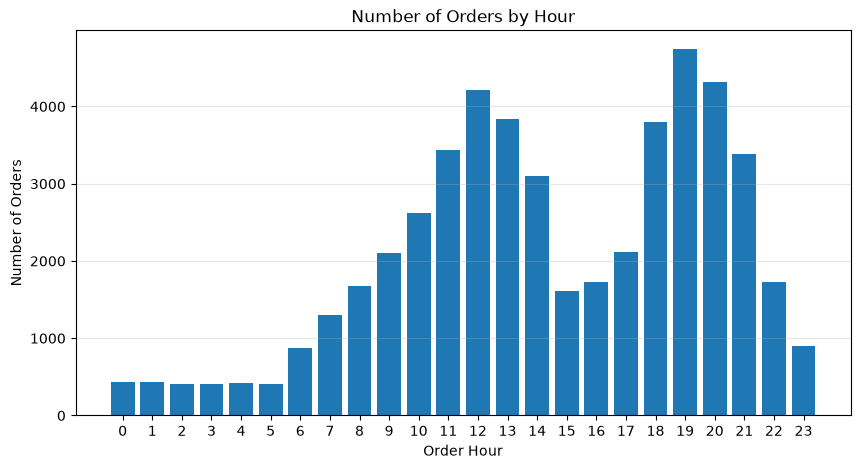

In [50]:
import matplotlib.pyplot as plt

orders_by_hour = df["order_hour"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(orders_by_hour.index, orders_by_hour.values)

plt.title("Number of Orders by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

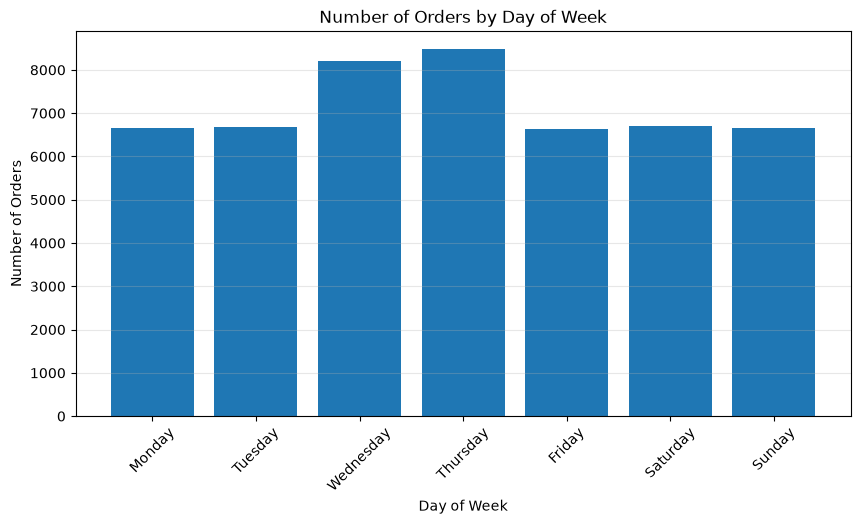

In [51]:
import matplotlib.pyplot as plt

orders_by_day = df["day_of_week"].value_counts()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

orders_by_day = orders_by_day.reindex(day_order)

plt.figure(figsize=(10, 5))
plt.bar(orders_by_day.index, orders_by_day.values)

plt.title("Number of Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

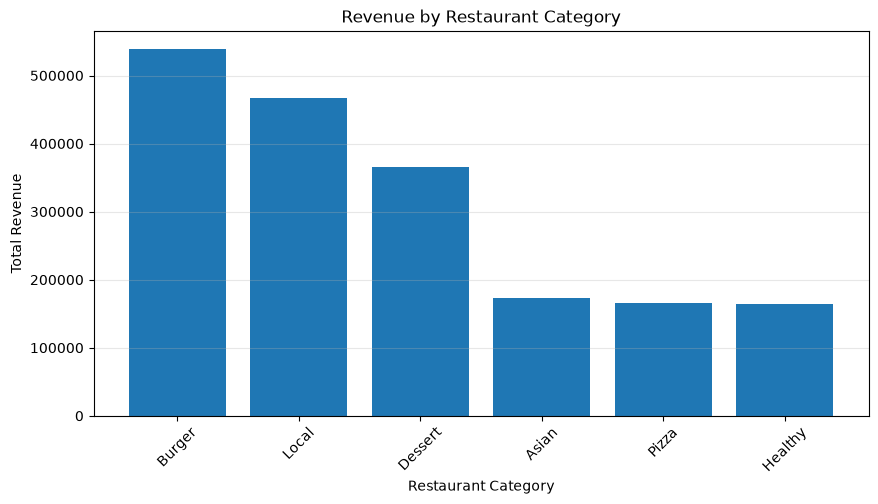

In [52]:
import matplotlib.pyplot as plt

revenue_by_category = (
    df[df["order_status"] == "Completed"]
    .groupby("restaurant_primary_category")["order_total"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(revenue_by_category.index, revenue_by_category.values)

plt.title("Revenue by Restaurant Category")
plt.xlabel("Restaurant Category")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

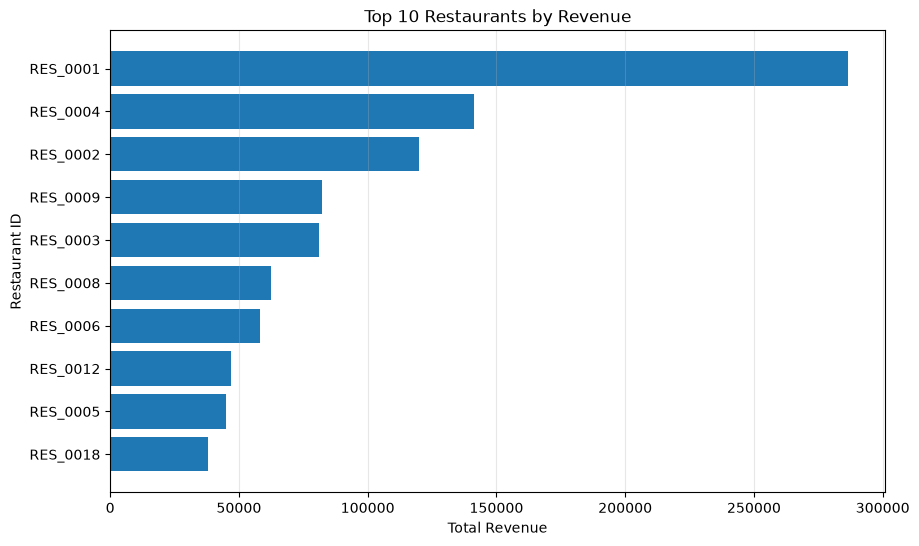

In [53]:
import matplotlib.pyplot as plt

top_10_restaurants = (
    df[df["order_status"] == "Completed"]
    .groupby("restaurant_id")["order_total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(top_10_restaurants.index, top_10_restaurants.values)

plt.title("Top 10 Restaurants by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Restaurant ID")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

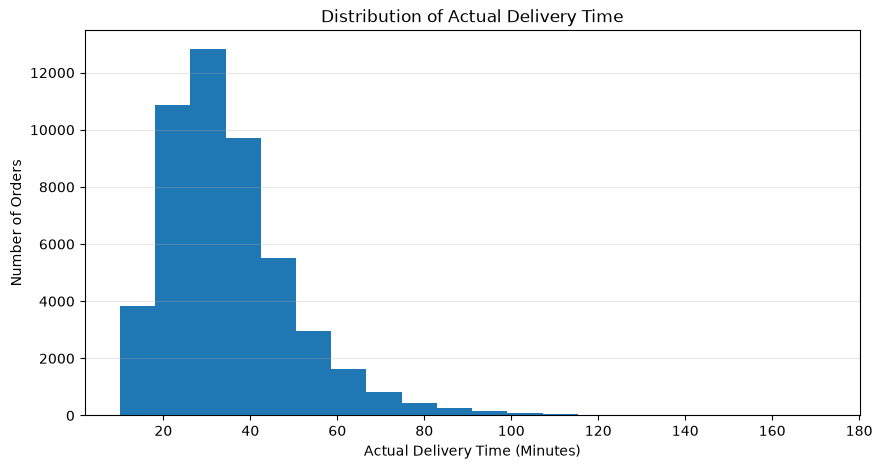

In [55]:
import matplotlib.pyplot as plt

delivery_times = df[df["order_status"] == "Completed"]["actual_delivery_time_minutes"]

plt.figure(figsize=(10, 5))
plt.hist(delivery_times, bins=20)

plt.title("Distribution of Actual Delivery Time")
plt.xlabel("Actual Delivery Time (Minutes)")
plt.ylabel("Number of Orders")

plt.grid(axis="y", alpha=0.3)

plt.show()

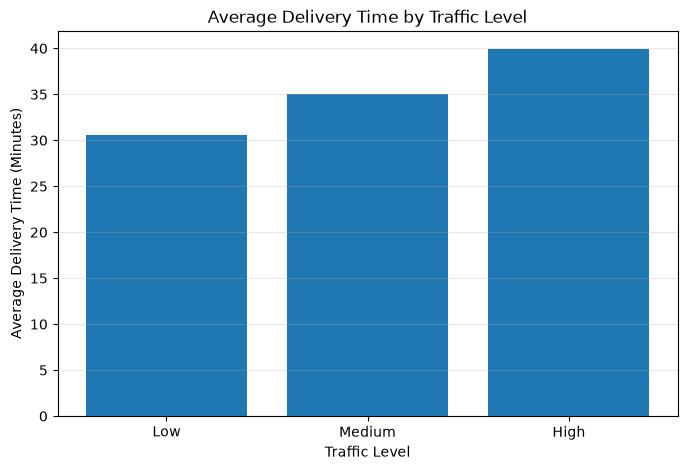

In [56]:
import matplotlib.pyplot as plt

avg_delivery_by_traffic = (
    df[df["order_status"] == "Completed"]
    .groupby("traffic_level")["actual_delivery_time_minutes"]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

plt.figure(figsize=(8, 5))
plt.bar(avg_delivery_by_traffic.index, avg_delivery_by_traffic.values)

plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Delivery Time (Minutes)")

plt.grid(axis="y", alpha=0.3)

plt.show()

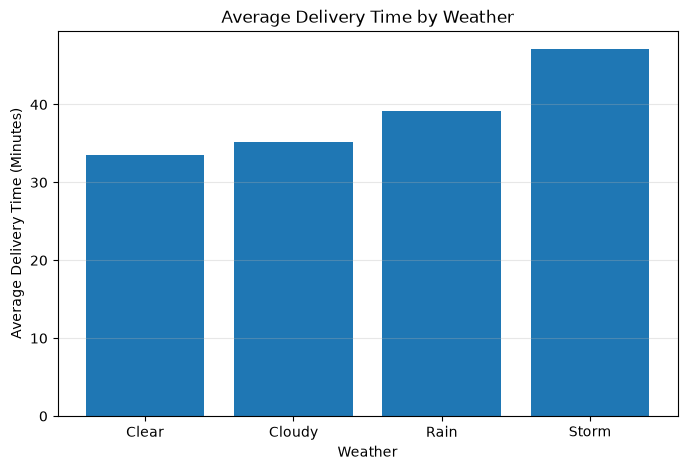

In [57]:
import matplotlib.pyplot as plt

avg_delivery_by_weather = (
    df[df["order_status"] == "Completed"]
    .groupby("weather")["actual_delivery_time_minutes"]
    .mean()
    .reindex(["Clear", "Cloudy", "Rain", "Storm"])
)

plt.figure(figsize=(8, 5))
plt.bar(avg_delivery_by_weather.index, avg_delivery_by_weather.values)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Delivery Time (Minutes)")

plt.grid(axis="y", alpha=0.3)

plt.show()

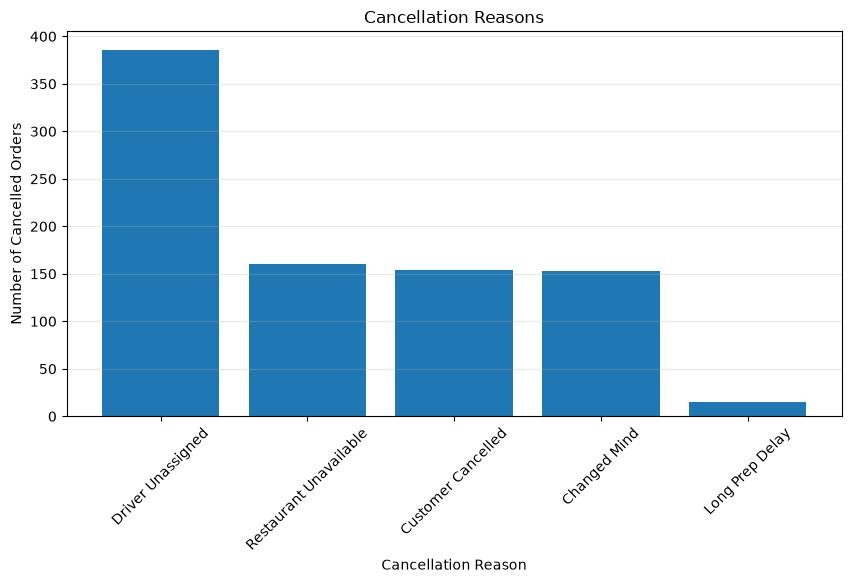

In [58]:
import matplotlib.pyplot as plt

cancellation_reasons = (
    df[df["order_status"] == "Cancelled"]["cancellation_reason"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(cancellation_reasons.index, cancellation_reasons.values)

plt.title("Cancellation Reasons")
plt.xlabel("Cancellation Reason")
plt.ylabel("Number of Cancelled Orders")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

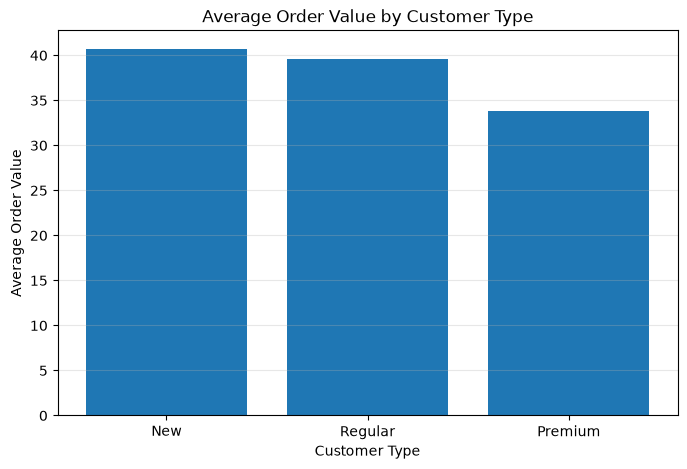

In [59]:
import matplotlib.pyplot as plt

aov_by_customer_type = (
    df[df["order_status"] == "Completed"]
    .groupby("customer_type")["order_total"]
    .mean()
    .reindex(["New", "Regular", "Premium"])
)

plt.figure(figsize=(8, 5))
plt.bar(aov_by_customer_type.index, aov_by_customer_type.values)

plt.title("Average Order Value by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Order Value")

plt.grid(axis="y", alpha=0.3)

plt.show()

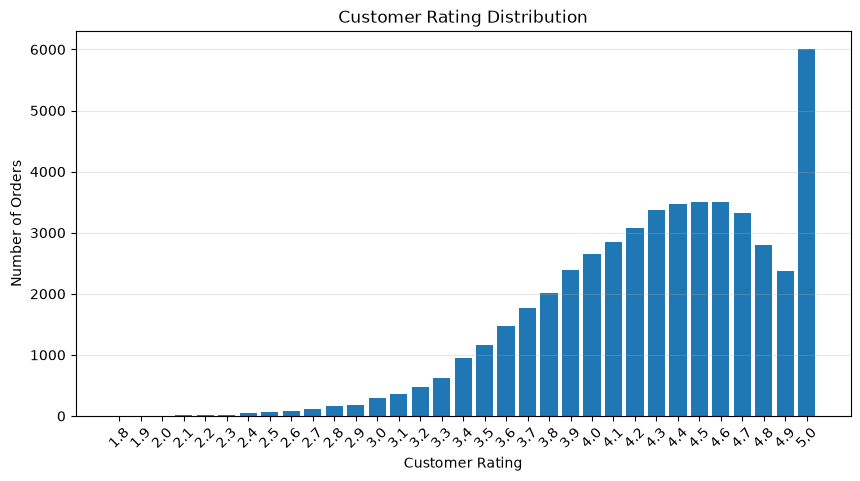

In [60]:
import matplotlib.pyplot as plt

customer_ratings = (
    df[df["order_status"] == "Completed"]["customer_rating"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.bar(customer_ratings.index.astype(str), customer_ratings.values)

plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()